### Shallow Agent

Shallow agents are characterized by their simple architecture and reactive nature. They operate on a loop-based design where the AI reads a user's prompt, decides on the necessary tool to call, gets the result, and repeats the process. This architecture is effective for quick requests but fails when tasks become complex, leading to issues such as context overflow, loss of goal, and lack of recovery mechanisms. 

Shallow agents rely entirely on the LLM's context window for their state, making them stateless and ephemeral. They are particularly well-suited for transactional tasks but struggle with tasks that require multiple steps or complex reasoning.

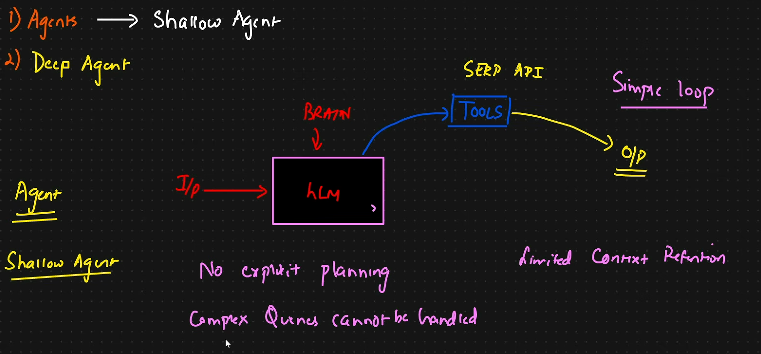

### ReAct Agent

A ReAct agent is an AI agent that uses the “reasoning and acting” (ReAct) framework to combine chain of thought (CoT) reasoning with external tool use. The ReAct framework enhances the ability of a large language model (LLM) to handle complex tasks and decision-making in agentic workflows.

First introduced by Yao and others in the 2023 paper, “ReACT: Synergizing Reasoning and Acting in Language Models,” ReAct can be understood most generally as a machine learning (ML) paradigm to integrate the reasoning and action-taking capabilities of LLMs.

The core challenge with ReAct agents is managing their iterative thought‑action‑observation loop, which can create reliability issues like infinite loops, hallucinated actions, high latency, and security risks.

Limitations:
1. This is a best improvent but still a Shallow Agent.
2. This is not SMART AGENT
3. This is just LLM + Tool (loop is happening)
4. No structure, no plan, no deep-reasoning, no state management

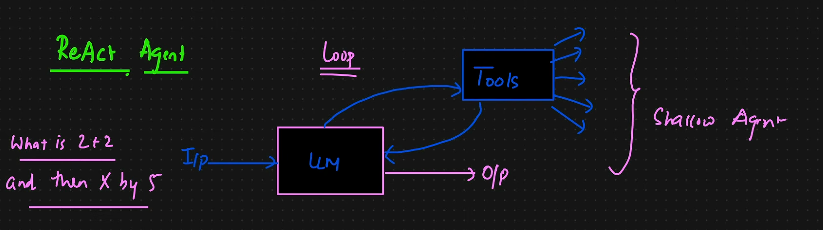


### Deep Agents overview

Build agents that can plan, use subagents, and leverage file systems for complex tasks

deepagents is a standalone library for building agents that can tackle complex, multi-step tasks. Built on LangGraph and inspired by applications like Claude Code, Deep Research, and Manus. Deep agents come with planning capabilities, file systems for context management, and the ability to spawn subagents.

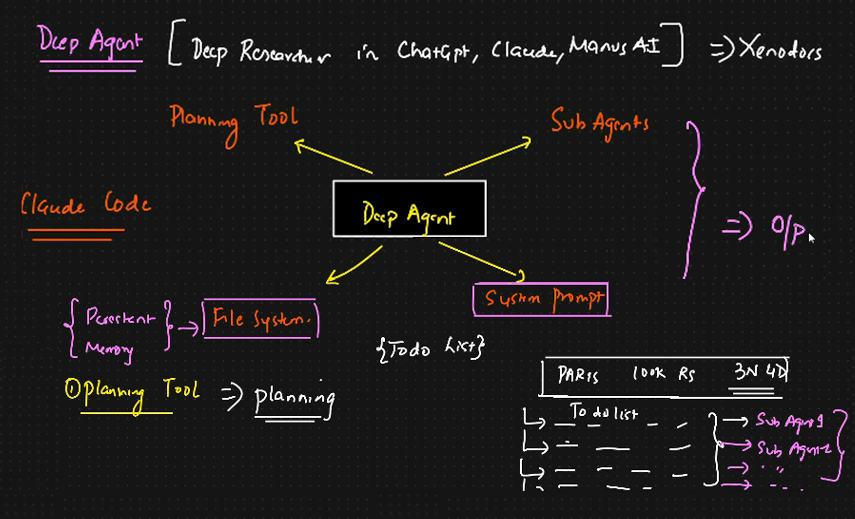

Example:

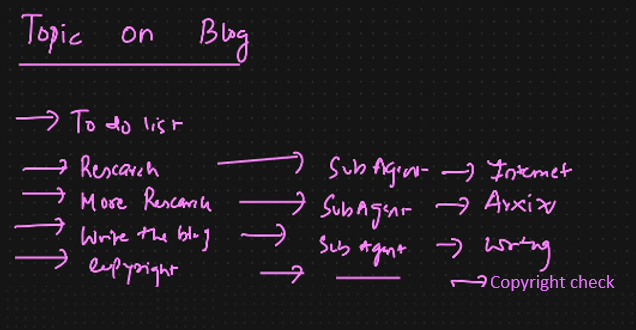



### When to use deep agents
Use deep agents when you need agents that can:

- Handle complex, multi-step tasks that require planning and decomposition
- Manage large amounts of context through file system tools
- Delegate work to specialized subagents for context isolation
- Persist memory across conversations and threads

In [1]:
# Basic deep agent

import os
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

In [2]:
# Tools- Internet search
from tavily import TavilyClient
from typing import Literal

tavily_client=TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))

def web_search(query:str,max_results:int=5,
topic: Literal["general","sports","news","finance"]="general",
include_raw_content:bool=False):
    """Run a web search"""
    return tavily_client.search(query,
    max_results=max_results,include_raw_content=include_raw_content,topic=topic)

In [3]:
from langchain.chat_models import init_chat_model

model=init_chat_model("groq:openai/gpt-oss-20b")
model

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.0', 'langchain': '1.5.0'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000021A530A03E0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000021A530ECA70>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

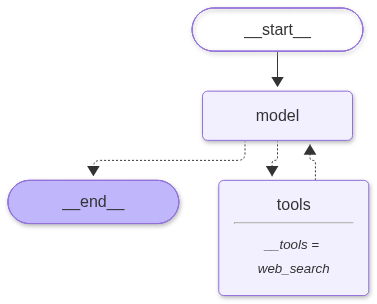

In [4]:
# Basic Agent in LangChain

from langchain.agents import create_agent

simple_agent=create_agent(
    model=model,
    tools=[web_search]
)
simple_agent

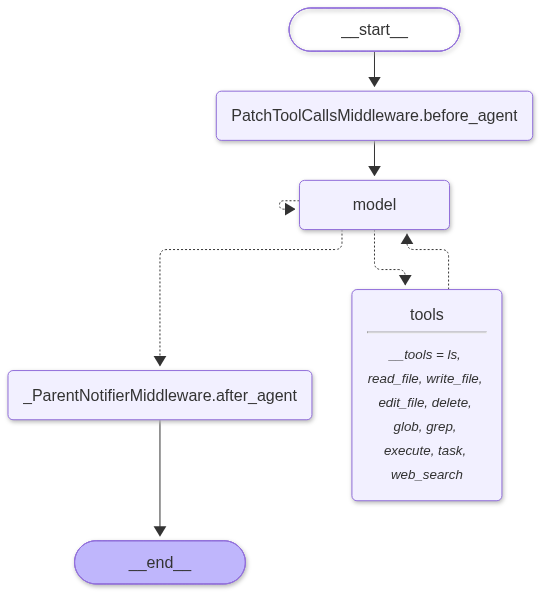

In [5]:
### Create a deep agent
## Prompt

## Agent

from deepagents import create_deep_agent

deepagent=create_deep_agent(
    model=model,
    tools=[web_search],
    system_prompt="Act as a researcher"
)
deepagent

In [6]:
result = deepagent.invoke({"messages": [{"role": "user", "content": "What is deepagent?"}]})
result

{'messages': [HumanMessage(content='What is deepagent?', additional_kwargs={}, response_metadata={}, id='96c2ad2d-8a05-4266-a6fb-6b91a6e4a83c'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'User asks: "What is deepagent?" We need to provide answer. Likely a tool? Might be a software? Could be a product. Let\'s search.', 'tool_calls': [{'id': 'fc_fa5fff51-02ab-45a9-9ca9-3bf0ad92d54a', 'function': {'arguments': '{"max_results":10,"query":"deepagent","topic":"general"}', 'name': 'web_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 67, 'prompt_tokens': 1979, 'total_tokens': 2046, 'completion_time': 0.072637359, 'completion_tokens_details': {'reasoning_tokens': 34}, 'prompt_time': 0.120117583, 'prompt_tokens_details': None, 'queue_time': 0.611580366, 'total_time': 0.192754942}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_8d13edce1d', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'm

In [9]:
result = deepagent.invoke({"messages": [{"role": "user", "content": "What is the difference between DeepAgent and ReAct Agent?"}]})
result

{'messages': [HumanMessage(content='What is the difference between DeepAgent and ReAct Agent?', additional_kwargs={}, response_metadata={}, id='47d586e1-2b1e-4c9d-827c-2a607ad5d825'),
  AIMessage(content='', additional_kwargs={'reasoning_content': "We need to answer: difference between DeepAgent and ReAct Agent. Likely referring to AI agent frameworks. Need to research. Use web search? Possibly known from literature. DeepAgent maybe a new agent architecture. ReAct is a framework combining reasoning and acting. Let's search web.", 'tool_calls': [{'id': 'fc_d74423a8-5ddd-45b9-b6fc-2ba2ae1a47e7', 'function': {'arguments': '{"include_raw_content":true,"max_results":5,"query":"DeepAgent","topic":"general"}', 'name': 'web_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 100, 'prompt_tokens': 1986, 'total_tokens': 2086, 'completion_time': 0.105393415, 'completion_tokens_details': {'reasoning_tokens': 58}, 'prompt_time': 0.138600497, 'prompt_tokens_detai

In [ ]:
result["messages"][-1].content

'**DeepAgent vs. ReAct Agent**  \n*(LangChain / LangGraph ecosystem)*  \n\n| Feature | ReAct Agent | DeepAgent |\n|---------|-------------|-----------|\n| **Basic loop** | `think → act → observe` (single LLM call → tool call → result → next turn). | Same core loop, but wrapped in a **hierarchical planner** that can spawn **sub‑agents** and maintain a **virtual file system** for context. |\n| **Planning** | None. The agent decides on the next tool call purely from the LLM’s immediate output. | Uses a *planner* (often a separate LLM call) to break a complex goal into sub‑goals, assign them to sub‑agents, and keep track of the overall plan. |\n| **Context Management** | Accumulates all turns in a single conversation history. On long runs, earlier constraints can “rot” out of the model’s attention window. | Each sub‑agent has its own isolated context; a *virtual file system* stores intermediate results, notes, and constraints. The main agent can refer back to these files without cluttering

In [ ]:
# The files created by the deep agent are stored in the result dictionary under the 'files' key. 
# They are used to store the context and information that the agent has gathered during its execution.

result['files']

{'/large_tool_results/fc_d74423a8-5ddd-45b9-b6fc-2ba2ae1a47e7': {'content': '{"query": "DeepAgent", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://tavily.com/knowledge/company/Y8KK2zX4mLhJ", "title": "DeepAgent", "content": "# DeepAgent\\nID: Y8KK2zX4mLhJ\\nWebsite: www.deepagent.app\\nHeadquarters: Rome, Latium, Italy\\nLinkedIn: www.linkedin.com/company/deepagent · 1,576 followers\\nIndustry: Technology, Information and Media\\nCompany type: Privately Held\\nFounded: 2024\\nBusiness model: B2B\\nSaaS: yes\\nSocial profiles: www.facebook.com/deepagentai, www.crunchbase.com/organization/deepagent [...] Description: DeepAgent è la soluzione AI che rivoluziona la gestione delle vendite, delle risorse umane e del customer care attraverso assistenti vocali intelligenti. Grazie all’esperienza combinata di FunnelConsulting, ResultConsulting e Otacon, portiamo sul mercato agenti AI avanzati, progettati per integrarsi nei processi aziendali e migliorarn

### What happened?

Your deep agent automatically:
- Planned its approach: Used the built-in write_todos tool to break down the research task
- Conducted research: Called the internet_search tool to gather information
- Managed context: Used file system tools (write_file, read_file) to offload large search results
- Spawned subagents (if needed): Delegated complex subtasks to specialized subagents
- Synthesized a report: Compiled findings into a coherent response

### Customizing Deep Agents

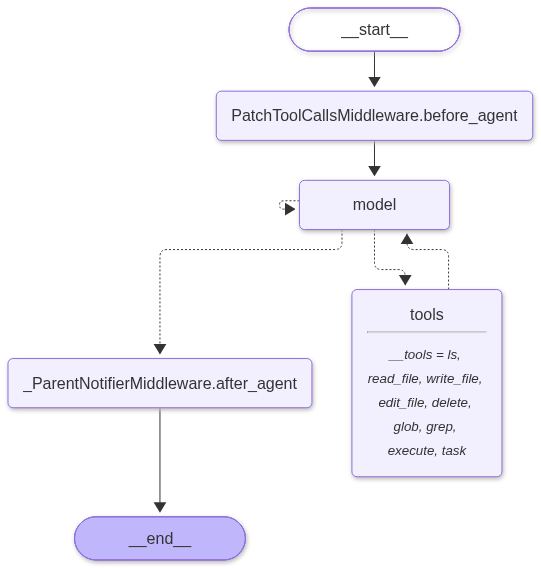

In [14]:
# Model
from langchain.chat_models import init_chat_model
from deepagents import create_deep_agent

model = init_chat_model(model="groq:openai/gpt-oss-20b")
agent = create_deep_agent(model=model)
agent

In [15]:
result = agent.invoke({"messages": [{"role": "user", "content": "What is DeepAgent?"}]})
result

{'messages': [HumanMessage(content='What is DeepAgent?', additional_kwargs={}, response_metadata={}, id='b3942c18-e7bf-4641-9a0d-b0198c53b9eb'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "What is DeepAgent?" Likely a product or project. We need to search. Use grep or glob. Let\'s search for "DeepAgent" in repository.', 'tool_calls': [{'id': 'fc_78debaa3-9114-47af-894b-52339bb103ad', 'function': {'arguments': '{"path":null,"pattern":"DeepAgent"}', 'name': 'glob'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 67, 'prompt_tokens': 1907, 'total_tokens': 1974, 'completion_time': 0.1032838, 'completion_tokens_details': {'reasoning_tokens': 38}, 'prompt_time': 0.097203406, 'prompt_tokens_details': None, 'queue_time': 0.368714962, 'total_time': 0.200487206}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_bb6a356524', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provide

### System Prompt
Deep agents come with a built-in system prompt inspired by Claude Code’s system prompt. The default system prompt contains detailed instructions for using the built-in planning tool, file system tools, and subagents.
Each deep agent tailored to a use case should include a custom system prompt specific to that use case.

In [16]:
from deepagents import create_deep_agent

research_instructions = """\
You are an expert researcher. Your job is to conduct \
thorough research, and then write a polished report. \
"""

agent = create_deep_agent(
    model=model,
    system_prompt=research_instructions,
)
result = agent.invoke({"messages": [{"role": "user", "content": "What is deepagent?"}]})
result

{'messages': [HumanMessage(content='What is deepagent?', additional_kwargs={}, response_metadata={}, id='2e9a38ac-b1fd-4589-a820-d97c0b2498c0'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "What is deepagent?" We need to provide an answer. The user didn\'t specify a location; maybe there\'s a file or a concept. We need to research. Let\'s search for "deepagent" in the repository.', 'tool_calls': [{'id': 'fc_d52c91d4-78db-42ae-8945-54f8c91e04e7', 'function': {'arguments': '{"path":null,"pattern":"deepagent"}', 'name': 'glob'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 78, 'prompt_tokens': 1932, 'total_tokens': 2010, 'completion_time': 0.085863562, 'completion_tokens_details': {'reasoning_tokens': 49}, 'prompt_time': 0.110721229, 'prompt_tokens_details': None, 'queue_time': 0.15694411, 'total_time': 0.196584791}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_a8c584dda7', 'service_tier': 'on_demand', 

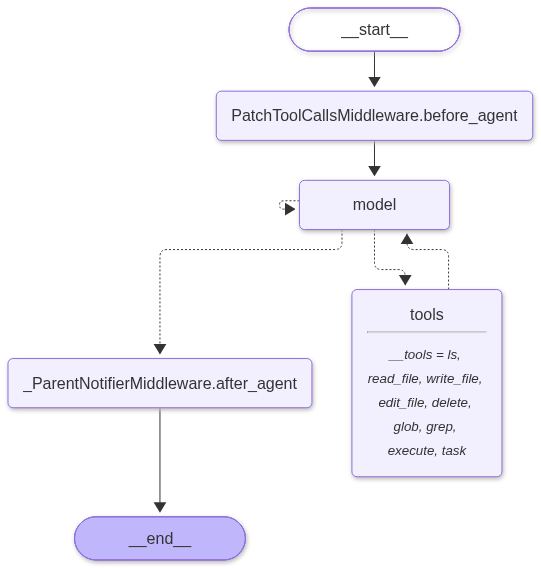

In [17]:
agent

In [18]:
### Tools
import os
from typing import Literal
from tavily import TavilyClient
from deepagents import create_deep_agent

tavily_client = TavilyClient(api_key=os.environ["TAVILY_API_KEY"])

def internet_search(
    query: str,
    max_results: int = 5,
    topic: Literal["general", "news", "finance"] = "general",
    include_raw_content: bool = False,
):
    """Run a web search"""
    return tavily_client.search(
        query,
        max_results=max_results,
        include_raw_content=include_raw_content,
        topic=topic,
    )

agent = create_deep_agent(
    model=model,
    tools=[internet_search]
)
result = agent.invoke({"messages": [{"role": "user", "content": "What is deepagent in Agentic AI?"}]})
result

{'messages': [HumanMessage(content='What is deepagent in Agentic AI?', additional_kwargs={}, response_metadata={}, id='485e242b-d729-45a0-83e9-55278cb0a2f8'),
  AIMessage(content='**DeepAgent in Agentic AI**\n\nIn the context of **Agentic AI**—the field that studies autonomous, goal‑oriented software agents that can perceive, reason, and act in complex environments—a **DeepAgent** refers to an agent whose decision‑making core is built around deep learning models (e.g., neural networks).  \n\nKey characteristics of a DeepAgent:\n\n| Feature | Description |\n|---------|-------------|\n| **Learning backbone** | Uses deep neural architectures (CNNs, RNNs, Transformers, etc.) to process raw sensory input (images, text, sensor streams). |\n| **Policy representation** | The agent’s policy (mapping from states to actions) is parameterized by a neural network, often trained via reinforcement learning (RL) or imitation learning. |\n| **End‑to‑end training** | The entire perception‑to‑action pipe